<a href="https://colab.research.google.com/github/Andrian0s/ML4NLP1-2026-Tutorial-Notebooks/blob/main/lectures_supplementary_code_samples/l10_gpt_companion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# L10 Companion: Generative Pretraining and GPT-Style Language Models

This notebook accompanies the L10 deck *Generative Pretraining and GPT-Style Language Models*. You inspect how causal masking enforces autoregressive ordering, trace representations through GPT-2, count where parameters sit, experiment with decoding rules, test KV caching, and probe prefix conditioning. Each N-numbered section names the lecture frames it replays:

N1. **The Mask Removes Future Keys Exactly:** Masking scores with $-\infty$ vs. zero; how softmax converts masked scores to exact zeros.
N2. **A Later Token Cannot Change Earlier Outputs:** Why causal attention restricts information flow; verifying output invariance across positions.
N3. **One Pass Gives $n$ Losses:** Computing next-token predictions and cross-entropy losses for an entire sequence in parallel vs. prefix passes.
N4. **Shapes Through GPT-2 and the Tied Head:** Tracing activations from token embeddings through 12 Transformer blocks and verifying head weight tying.
N5. **Where the Parameters Are:** Deriving parameter counts from architecture hyperparameters ($|V|, n_{\max}, d, L$) and comparing block vs. embedding shares.
N6. **Temperature, Top-$k$, Top-$p$ on the Slide Logits:** Controlling sharpness and diversity in next-token sampling on slide logits and real GPT-2 distributions.
N7. **The Decoding Loop With and Without KV Cache:** Step-by-step greedy generation; measuring speedup and inspecting stored key-value cache shapes.
N8. **The Prefix Specifies the Task:** Conditioning GPT-2 on zero-shot and few-shot translation prompts; analyzing format adherence vs. correctness.

The notebook supports conceptual understanding through concrete code experiments; it is not a graded assignment.

Time estimates exclude initial model downloads.
- **Core (approx. 40–50 minutes):** N1–N5.
- **Explore (approx. 30–40 minutes):** N6–N8.


In [1]:
# Dependencies: Python, PyTorch, Transformers, NumPy, Matplotlib.
# Only Colab installs missing packages.
import sys
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    %pip install -q "transformers>=4.45" "torch>=2.0" "numpy>=1.24" "matplotlib>=3.7"

import importlib.metadata
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from transformers.utils import logging as hf_logging
hf_logging.set_verbosity_error()
hf_logging.disable_progress_bar()

np.set_printoptions(precision=3, suppress=True)
torch.set_printoptions(precision=3, sci_mode=False)
np.random.seed(42)
torch.manual_seed(42)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {DEVICE}")
for package in ("torch", "transformers", "numpy", "matplotlib"):
    print(f"{package}: {importlib.metadata.version(package)}")


Device: cpu
torch: 2.11.0
transformers: 5.5.4
numpy: 2.4.4
matplotlib: 3.11.2


## N1. The Mask Removes Future Keys Exactly

**Adding $-\infty$ before the softmax gives exact zeros; adding 0 (or zeroing scores) does not.**

Replays: *Mask Build 1: Which Scores Are Forbidden?; Mask Build 2: Add $-\infty$ Before the Softmax; Mask Build 3: Softmax Gives Exact Zeros*.

In causal self-attention, query position $i$ must not attend to key position $j$ whenever $j > i$.
The causal mask $M \in \mathbb{R}^{n \times n}$ adds $-\infty$ to forbidden entries before applying the row-wise softmax:
$$M_{ij} = \begin{cases} 0 & j \le i, \\ -\infty & j > i. \end{cases}$$

Consider the toy $4 \times 4$ score matrix from the lecture:
Row 2 (index 1) has scores $0.1$ and $0.6$ for allowed positions $j=0, 1$, and forbidden scores for $j=2, 3$.

**Predict:** What attention weights will row 2 receive after applying the $-\infty$ mask and softmax? What would happen if we instead set the forbidden scores to $0$?


In [2]:
# Score matrix from the lecture (4 positions)
scores = torch.tensor([
    [0.5, 0.2, 0.1, 0.3],
    [0.1, 0.6, 0.3, 0.4],
    [0.2, 0.4, 0.8, 0.1],
    [0.3, 0.1, 0.2, 0.7]
])

# 1. Causal mask with -inf above diagonal
mask = torch.triu(torch.full_like(scores, float('-inf')), diagonal=1)
masked_scores = scores + mask
weights_masked = F.softmax(masked_scores, dim=-1)

# 2. Flawed alternative: setting forbidden scores to 0 instead of -inf
zero_masked_scores = scores.clone()
zero_masked_scores.masked_fill_(torch.triu(torch.ones_like(scores, dtype=torch.bool), diagonal=1), 0.0)
weights_zero = F.softmax(zero_masked_scores, dim=-1)

print("Attention weights with -inf causal mask:")
print(weights_masked)
print(f"Row 2 weights: {weights_masked[1].tolist()}")

print("\nAttention weights when future scores are set to 0:")
print(weights_zero)
print(f"Row 2 weights: {weights_zero[1].tolist()}")


Attention weights with -inf causal mask:
tensor([[1.000, 0.000, 0.000, 0.000],
        [0.378, 0.622, 0.000, 0.000],
        [0.247, 0.302, 0.451, 0.000],
        [0.237, 0.194, 0.215, 0.354]])
Row 2 weights: [0.3775406777858734, 0.622459352016449, 0.0, 0.0]

Attention weights when future scores are set to 0:
tensor([[0.355, 0.215, 0.215, 0.215],
        [0.224, 0.370, 0.203, 0.203],
        [0.206, 0.251, 0.375, 0.168],
        [0.237, 0.194, 0.215, 0.354]])
Row 2 weights: [0.22429591417312622, 0.36980143189430237, 0.2029513269662857, 0.2029513269662857]


### Read the result

Compare row 2 across both methods. With $-\infty$, $\exp(-\infty) = 0$, so forbidden positions receive weight exactly $0.000$, and the allowed positions receive:
$$\operatorname{softmax}(0.1, 0.6) = \left(\frac{e^{0.1}}{e^{0.1}+e^{0.6}}, \frac{e^{0.6}}{e^{0.1}+e^{0.6}}\right) \approx (0.378, 0.622)$$
Notice that the slide graphic truncates these values to $0.37$ and $0.62$.
When setting scores to $0$, $\exp(0) = 1.0$, so forbidden positions steal probability mass ($0.203$ each) and distort the distribution over allowed tokens.

**Check yourself.**

1. Why does setting forbidden attention scores to $0$ fail to eliminate future information?
2. Why is the first row of a causal attention matrix always $[1.0, 0, 0, \dots, 0]$ regardless of score values?
3. In a causal attention matrix, rows sum to $1$. Do columns sum to $1$? Why or why not?

<details>
<summary>Solution: Mask mechanics, first-row triviality, and row vs. column sums</summary>

1. Softmax exponentiates scores before normalizing: $\exp(0) = 1 > 0$. Only $\exp(-\infty) = 0$ yields zero numerator and zero probability weight. Setting scores to $0$ merely treats future tokens as having a score equal to $0$, which competes with negative or small positive scores.
2. For position $0$ (the first token), all positions $j > 0$ are masked to $-\infty$. There is only one unmasked key ($j=0$). Softmax over a single candidate trivially yields $\frac{\exp(s_{00})}{\exp(s_{00})} = 1.0$.
3. No. Rows are probability distributions over keys for each query token ($\sum_j A_{ij} = 1$). Columns show how much different queries attend to a given key (incoming attention). Earlier tokens can be attended to by many subsequent tokens (column sum can exceed $1$), while the last token can only be attended to by itself (column sum $\le 1$, since only the last row attends to it).
</details>


## N2. A Later Token Cannot Change Earlier Outputs

**With causal masking, output row $i$ depends strictly on input tokens $j \le i$.**

Replays: *Causal Self-Attention; Causal Attention in Equations*.

A crucial property of causal attention is that future tokens cannot leak into earlier representations:
$$A = \operatorname{softmax}_{\text{row}}\!\left(\frac{QK^\top}{\sqrt{d_k}} + M\right) V$$
Because $M$ zeros out attention to all $j > i$, representation $\mathbf{h}_i$ is invariant to any changes made at positions $k > i$.

Furthermore, because feed-forward networks (FFN), residual additions, and LayerNorm in standard Transformers operate position-wise (independently per token row), this causal separation holds across all $L$ layers of the Transformer stack.

**Predict:** If we change token 4 (the 5th token in 0-indexed notation), which output rows will change in a single masked attention head? Which output rows will change if attention is unmasked? Does this hold through all 12 blocks of pretrained GPT-2?


In [3]:
# Part A: Synthetic single attention head
torch.manual_seed(42)
n_seq = 5
d_k = 8
X = torch.randn(1, n_seq, d_k)
W_Q = torch.randn(d_k, d_k) / d_k ** 0.5  # scaled init keeps the softmax unsaturated
W_K = torch.randn(d_k, d_k) / d_k ** 0.5
W_V = torch.randn(d_k, d_k) / d_k ** 0.5

def causal_attention(x, masked=True):
    Q = x @ W_Q
    K = x @ W_K
    V = x @ W_V
    scores = (Q @ K.transpose(-2, -1)) / (d_k ** 0.5)
    if masked:
        mask = torch.triu(torch.full((scores.size(-2), scores.size(-1)), float('-inf')), diagonal=1)
        scores = scores + mask
    weights = F.softmax(scores, dim=-1)
    return weights @ V

# Modify token 4 (the last token)
X_mod = X.clone()
X_mod[0, 4, :] += torch.randn(d_k)

out_orig_masked = causal_attention(X, masked=True)
out_mod_masked = causal_attention(X_mod, masked=True)

out_orig_unmasked = causal_attention(X, masked=False)
out_mod_unmasked = causal_attention(X_mod, masked=False)

print("Single Head Causal Attention (Token 4 changed):")
for i in range(n_seq):
    diff = (out_orig_masked[0, i] - out_mod_masked[0, i]).abs().max().item()
    print(f"  Row {i}: max abs diff = {diff:.2e}")

print("\nSingle Head Unmasked Attention (Token 4 changed):")
for i in range(n_seq):
    diff = (out_orig_unmasked[0, i] - out_mod_unmasked[0, i]).abs().max().item()
    print(f"  Row {i}: max abs diff = {diff:.2e}")


Single Head Causal Attention (Token 4 changed):
  Row 0: max abs diff = 0.00e+00
  Row 1: max abs diff = 0.00e+00
  Row 2: max abs diff = 0.00e+00
  Row 3: max abs diff = 0.00e+00
  Row 4: max abs diff = 2.20e+00

Single Head Unmasked Attention (Token 4 changed):
  Row 0: max abs diff = 5.60e-01
  Row 1: max abs diff = 4.58e-01
  Row 2: max abs diff = 1.79e-02
  Row 3: max abs diff = 2.89e-01
  Row 4: max abs diff = 2.20e+00


In [4]:
# Part B: Verifying causality across all 12 blocks of GPT-2
from transformers import GPT2LMHeadModel, GPT2Tokenizer

print("Loading GPT-2 (124M)...")
tokenizer = GPT2Tokenizer.from_pretrained("gpt2")
model = GPT2LMHeadModel.from_pretrained("gpt2")
model.to(DEVICE)
model.eval()

# Two sentences differing only in the final token
text_orig = "The quick brown fox jumps"
ids_orig = tokenizer.encode(text_orig, return_tensors="pt").to(DEVICE)

# Replace ' jumps' with ' runs'
ids_mod = ids_orig.clone()
ids_mod[0, -1] = tokenizer.encode(" runs", add_prefix_space=True)[0]

with torch.no_grad():
    h_orig = model(ids_orig, output_hidden_states=True).hidden_states[-1]
    h_mod = model(ids_mod, output_hidden_states=True).hidden_states[-1]

print(f"Original sequence: {[tokenizer.decode(t) for t in ids_orig[0]]}")
print(f"Modified sequence: {[tokenizer.decode(t) for t in ids_mod[0]]}")
print("\nGPT-2 final normalized states H (after the last block and final LayerNorm):")
for i in range(ids_orig.shape[1]):
    close = torch.allclose(h_orig[0, i], h_mod[0, i], atol=1e-5)
    max_diff = (h_orig[0, i] - h_mod[0, i]).abs().max().item()
    tok_str = tokenizer.decode(ids_orig[0, i])
    print(f"  Row {i} ({tok_str!r:<8}): identical? {close:<5} (max abs diff = {max_diff:.2e})")


Loading GPT-2 (124M)...


Original sequence: ['The', ' quick', ' brown', ' fox', ' jumps']
Modified sequence: ['The', ' quick', ' brown', ' fox', ' runs']

GPT-2 final normalized states H (after the last block and final LayerNorm):
  Row 0 ('The'   ): identical? 1     (max abs diff = 0.00e+00)
  Row 1 (' quick'): identical? 1     (max abs diff = 0.00e+00)
  Row 2 (' brown'): identical? 1     (max abs diff = 0.00e+00)
  Row 3 (' fox'  ): identical? 1     (max abs diff = 0.00e+00)
  Row 4 (' jumps'): identical? 0     (max abs diff = 3.46e+01)


### Read the result

In the causal attention head and in the final normalized states of GPT-2 (after all 12 blocks), rows $0$ through $3$ are bitwise identical (max difference $0$). Only row $4$ changes.
Without the causal mask, modifying token $4$ alters the key matrix $K$ and value matrix $V$, so every earlier row changes as well (row 2 only slightly, because it attends little to position 4).

**Check yourself.**

1. In a standard Transformer block (Self-Attention, FFN, LayerNorm, Residual Addition), which operation is the *only* one that mixes representations across sequence positions?
2. What would happen to causality if LayerNorm normalized across the sequence length dimension instead of across the embedding dimension $d$?

<details>
<summary>Solution: Operations mixing positions and normalization axes</summary>

1. Attention is the only operation that mixes positions. The FFN applies identical transformations to each position vector independently ($1 \times 1$ convolutions across sequence length). Residual addition is elementwise per position. LayerNorm normalizes across channels (hidden dimension $d$) independently for each token.
2. If LayerNorm normalized across sequence positions (e.g., computing mean and variance across tokens $0, \dots, n-1$), every position's normalized value would depend on summary statistics of future tokens. Information from future tokens would leak into earlier positions, completely violating the causal guarantee.
</details>


## N3. One Pass Gives $n$ Losses

**One forward pass yields the exact same next-token distributions as $n$ separate prefix passes.**

Replays: *One Pass, $n$ Losses*.

As on the slide, a training text $x_1, \dots, x_{n+1}$ gives $n$ input positions $x_1, \dots, x_n$, each with its given next token as target. Because attention is causal, one forward pass over the inputs computes the next-token distribution for every prefix:
- position $1$ ($x_1$) predicts $x_2$,
- position $2$ ($x_1, x_2$) predicts $x_3$,
- $\dots$
- position $n$ ($x_1, \dots, x_n$) predicts $x_{n+1}$.

At training time, we do not run $n$ separate prefix passes. We feed the sequence once, read the probability matrix $\Pi \in \mathbb{R}^{n \times |V|}$, and compute the loss at each position:
$$\ell_t = -\log \Pi_{t, x_{t+1}}, \qquad \mathcal{L} = \frac{1}{n} \sum_{t=1}^{n} \ell_t$$

We test this on the text from the lecture slide: **"So long and thanks for"**. It has 5 tokens, so $n = 4$ input positions (`So` … `thanks`) with targets `long` … `for`, exactly the four columns of the slide.

**Predict:** Will position 2's output distribution from the full 5-token pass be identical to running GPT-2 on the prefix "So long" alone? How many loss terms does this 5-token text give, and why does `for` appear only as a target?


In [5]:
text = "So long and thanks for"
inputs = tokenizer(text, return_tensors="pt").to(DEVICE)
input_ids = inputs.input_ids # [1, 5]
tokens = [tokenizer.decode(t) for t in input_ids[0]]

print(f"Tokenized sequence (length {input_ids.shape[1]}):")
for i, (tok_id, tok_str) in enumerate(zip(input_ids[0], tokens)):
    print(f"  Pos {i}: id={tok_id.item():<5} token={tok_str!r}")

# Full pass
with torch.no_grad():
    out_full = model(**inputs)
    logits_full = out_full.logits[0] # [5, 50257]

# Compare each position against separate prefix passes
print("\nComparing full pass logits with separate prefix passes:")
for i in range(1, len(tokens) + 1):
    prefix_ids = input_ids[:, :i]
    with torch.no_grad():
        out_prefix = model(prefix_ids)
    logits_prefix = out_prefix.logits[0, -1]
    max_diff = (logits_full[i - 1] - logits_prefix).abs().max().item()
    print(f"  Pos {i-1} ({tokens[i-1]!r:<10}): max abs logit diff = {max_diff:.2e}")

# Compute per-position losses
# Targets: token at pos 1 for prediction at pos 0, etc.
targets = input_ids[0, 1:] # [4]
pred_logits = logits_full[:-1] # [4, 50257]
probs = F.softmax(pred_logits, dim=-1)
losses = F.cross_entropy(pred_logits, targets, reduction='none')

print("\nPer-position loss table:")
print(f"{'Pos':<5}{'Input (x_t)':<15}{'Target (x_{t+1})':<18}{'P(target)':<15}{'Loss (ell_t)':<12}")
print("-" * 65)
for t in range(len(targets)):
    p_tgt = probs[t, targets[t]].item()
    loss_t = losses[t].item()
    print(f"{t:<5}{tokens[t]!r:<15}{tokens[t+1]!r:<18}{p_tgt:<15.4f}{loss_t:<12.4f}")

mean_loss = losses.mean().item()
print(f"\nMean loss across the n = {len(targets)} input positions: {mean_loss:.4f}")

# Compare with Hugging Face's built-in loss computation
with torch.no_grad():
    hf_loss = model(input_ids, labels=input_ids).loss.item()
print(f"Hugging Face model(..., labels=input_ids).loss: {hf_loss:.4f}")
print(f"Difference: {abs(mean_loss - hf_loss):.2e}")


Tokenized sequence (length 5):
  Pos 0: id=2396  token='So'
  Pos 1: id=890   token=' long'
  Pos 2: id=290   token=' and'
  Pos 3: id=5176  token=' thanks'
  Pos 4: id=329   token=' for'

Comparing full pass logits with separate prefix passes:
  Pos 0 ('So'      ): max abs logit diff = 1.26e-04
  Pos 1 (' long'   ): max abs logit diff = 9.16e-05
  Pos 2 (' and'    ): max abs logit diff = 9.16e-05
  Pos 3 (' thanks' ): max abs logit diff = 0.00e+00
  Pos 4 (' for'    ): max abs logit diff = 0.00e+00

Per-position loss table:
Pos  Input (x_t)    Target (x_{t+1})  P(target)      Loss (ell_t)
-----------------------------------------------------------------
0    'So'           ' long'           0.0008         7.1520      
1    ' long'        ' and'            0.0047         5.3565      
2    ' and'         ' thanks'         0.0002         8.3313      
3    ' thanks'      ' for'            0.4442         0.8115      

Mean loss across the n = 4 input positions: 5.4128
Hugging Face model(..

### Read the result

1. The maximum absolute difference between the full pass logits and individual prefix passes is $\le 1.3 \times 10^{-4}$ (numerical float precision differences). The full pass computes exact prefix predictions simultaneously.
2. In the loss table, predicting `' thanks'` after `'So long and'` has a relatively low probability ($0.0002$, loss $8.3313$), whereas predicting `' for'` after `' thanks'` has high probability ($0.4442$, loss $0.8115$).
3. The mean loss across the $n = 4$ positions ($5.4128$) matches Hugging Face's internal `.loss` exactly.

**Check yourself.**

1. Why does the final token `for` appear only as a target, never as an input position with its own loss?
2. What does "teacher forcing" mean in the context of this parallel training pass?

<details>
<summary>Solution: Final token loss and teacher forcing</summary>

1. A text of $n+1$ tokens gives $n$ next-token pairs ($x_1 \to x_2, \dots, x_n \to x_{n+1}$). The final token has no observed successor, so it serves only as the target of position $n$; it would become an input position only if a further token (e.g. `<|endoftext|>`) followed.
2. In autoregressive generation, errors compound because each step conditions on previously generated tokens. In training with teacher forcing, the model always conditions on the true ground-truth prefix tokens regardless of what probabilities the model assigned at earlier positions.
</details>


## N4. Shapes Through GPT-2 and the Tied Head

**$H$ is $n \times d$, $\Pi$ is $n \times |V|$, and the language-model head reuses the token embedding matrix.**

Replays: *GPT-2: From Tokens to Next-Token Probabilities; The Language-Model Head*.

For an input sequence of length $n$:
1. **Input Embeddings:** Token embeddings $W_E \in \mathbb{R}^{|V| \times d}$ and positional embeddings $W_P \in \mathbb{R}^{n_{\max} \times d}$ sum to produce an initial representation $H^{(0)} \in \mathbb{R}^{n \times d}$.
2. **Transformer Blocks:** Each of the $L=12$ blocks preserves the shape: $H^{(l)} \in \mathbb{R}^{n \times d}$.
3. **Final LayerNorm:** Normalizes across dimension $d$: $H = \operatorname{LayerNorm}(H^{(12)}) \in \mathbb{R}^{n \times d}$.
4. **Language-Model Head (Weight Tying):** The output projection matrix is tied to the token embedding matrix:
   $$\Pi = \operatorname{softmax}(H W_E^\top) \in \mathbb{R}^{n \times |V|}$$

We inspect these shapes on the 5 tokens from Section N3 and verify weight tying directly in memory.

**Predict:** For $n=5, d=768, |V|=50,257$, what are the exact tensor dimensions of $H^{(l)}$, the final normalized hidden state $H$, and the output logits?


In [6]:
with torch.no_grad():
    out = model(**inputs, output_hidden_states=True)

# 1. Inspect hidden state shapes
hidden_states = out.hidden_states # Tuple of length 13 (L0 embedding + 12 blocks)
print(f"Number of hidden state tensors: {len(hidden_states)}")
print(f"Layer 0 (Embedding Output): {list(hidden_states[0].shape)}")
for layer in range(1, 13):
    print(f"Block {layer:2d} Output:          {list(hidden_states[layer].shape)}")

# 2. Inspect weight tying: lm_head vs wte
wte_weight = model.transformer.wte.weight
lm_head_weight = model.lm_head.weight

print(f"\nToken embedding matrix (wte) shape:    {list(wte_weight.shape)}")
print(f"Language model head (lm_head) shape:   {list(lm_head_weight.shape)}")

ptr_wte = wte_weight.data_ptr()
ptr_head = lm_head_weight.data_ptr()
is_tied = (ptr_wte == ptr_head)
print(f"wte memory pointer:     {ptr_wte}")
print(f"lm_head memory pointer: {ptr_head}")
print(f"Are weights physically tied in memory? {is_tied}")

# 3. Manually recompute logits from final hidden states: H @ wte.T
H_final = hidden_states[-1] # Shape [1, n, d] (already normalized by ln_f in HF GPT-2)
recomputed_logits = H_final @ wte_weight.T

diff_logits = (out.logits - recomputed_logits).abs().max().item()
print(f"\nOutput logits shape: {list(out.logits.shape)}")
print(f"Max abs diff between model.logits and H @ wte.T: {diff_logits:.2e}")


Number of hidden state tensors: 13
Layer 0 (Embedding Output): [1, 5, 768]
Block  1 Output:          [1, 5, 768]
Block  2 Output:          [1, 5, 768]
Block  3 Output:          [1, 5, 768]
Block  4 Output:          [1, 5, 768]
Block  5 Output:          [1, 5, 768]
Block  6 Output:          [1, 5, 768]
Block  7 Output:          [1, 5, 768]
Block  8 Output:          [1, 5, 768]
Block  9 Output:          [1, 5, 768]
Block 10 Output:          [1, 5, 768]
Block 11 Output:          [1, 5, 768]
Block 12 Output:          [1, 5, 768]

Token embedding matrix (wte) shape:    [50257, 768]
Language model head (lm_head) shape:   [50257, 768]
wte memory pointer:     481871671251
lm_head memory pointer: 481871671251
Are weights physically tied in memory? True

Output logits shape: [1, 5, 50257]
Max abs diff between model.logits and H @ wte.T: 0.00e+00


### Read the result

Every layer maintains the representation shape $[1, 5, 768]$. The output logits have shape $[1, 5, 50257]$.
The memory pointers for `model.transformer.wte.weight` and `model.lm_head.weight` are identical, proving that the head does not allocate new parameters.

**Check yourself.**

1. How many parameters does weight tying save in GPT-2 small ($|V|=50,257, d=768$)?
2. What is the semantic difference between using a row of $W_E$ at the input versus at the output head?

<details>
<summary>Solution: Parameter savings and input vs. output dual role</summary>

1. A separate linear head without bias would require $|V| \times d = 50,257 \times 768 = 38,597,376$ parameters (approx. $38.6$ million parameters, or $31\%$ of the model).
2. At the input, row $v$ of $W_E$ acts as a feature lookup: it translates a discrete token index into a continuous vector representation $\mathbf{e}_v \in \mathbb{R}^d$. At the output head, row $v$ acts as a linear classifier weight: computing the dot product $\mathbf{h}_t \cdot \mathbf{e}_v$ measures the compatibility of context representation $\mathbf{h}_t$ with token $v$.
</details>


## N5. Where the Parameters Are

**The parameter counts follow directly from $|V|, n_{\max}, d, L$ and the FFN expansion factor.**

Replays: *GPT-2 Small in Numbers*.

Recall the architectural hyperparameters of **GPT-2 Small**:
- Vocabulary size $|V| = 50,257$
- Context length $n_{\max} = 1,024$
- Hidden dimension $d = 768$
- Number of layers $L = 12$
- Attention heads $h = 12$ ($d_k = d/h = 64$)
- FFN inner dimension $d_{\text{ffn}} = 4d = 3,072$

Let us derive the theoretical parameter counts:
1. **Token Embeddings:** $|V| \times d = 50,257 \times 768 = 38,597,376$ ($38.6\text{M}$)
2. **Positional Embeddings:** $n_{\max} \times d = 1,024 \times 768 = 786,432$ ($0.8\text{M}$)
3. **Attention Weights (12 blocks):** Each block has $W_Q, W_K, W_V$ and projection $W_O$, each of size $d \times d$.
   $$4 \times d^2 = 4 \times 768^2 = 2,359,296 \text{ per block} \implies 12 \times 2.36\text{M} = 28,311,552\text{ (28.3M)}$$
4. **FFN Weights (12 blocks):** Each block expands $d \to 4d$ and contracts $4d \to d$.
   $$2 \times d \times 4d = 8d^2 = 8 \times 768^2 = 4,718,592 \text{ per block} \implies 12 \times 4.72\text{M} = 56,623,104\text{ (56.6M)}$$
5. **Rule of Thumb ($12Ld^2$):**
   $$\text{Attention} + \text{FFN} = 4Ld^2 + 8Ld^2 = 12Ld^2 = 12 \times 12 \times 768^2 = 84,934,656\text{ (84.9M)}$$

**Predict:** Calculate the proportion of parameters inside the Transformer blocks that belong to the FFN vs. Attention. What fraction of the total model parameters is in the token embedding matrix?


In [7]:
param_groups = {
    "Token Embeddings (wte)": 0,
    "Position Embeddings (wpe)": 0,
    "Attention Weights": 0,
    "Attention Biases": 0,
    "FFN Weights": 0,
    "FFN Biases": 0,
    "LayerNorms (Weights & Biases)": 0,
}

for name, param in model.named_parameters():
    num = param.numel()
    if "wte" in name:
        param_groups["Token Embeddings (wte)"] += num
    elif "wpe" in name:
        param_groups["Position Embeddings (wpe)"] += num
    elif "attn.c_attn.weight" in name or "attn.c_proj.weight" in name:
        param_groups["Attention Weights"] += num
    elif "attn.c_attn.bias" in name or "attn.c_proj.bias" in name:
        param_groups["Attention Biases"] += num
    elif "mlp.c_fc.weight" in name or "mlp.c_proj.weight" in name:
        param_groups["FFN Weights"] += num
    elif "mlp.c_fc.bias" in name or "mlp.c_proj.bias" in name:
        param_groups["FFN Biases"] += num
    elif "ln" in name:
        param_groups["LayerNorms (Weights & Biases)"] += num

total_counted = sum(param_groups.values())
total_model = sum(p.numel() for p in model.parameters())

print(f"{'Parameter Group':<32}{'Exact Count':>15}{'Millions':>12}{'Share (%)':>12}")
print("-" * 71)
for group, count in param_groups.items():
    share = (count / total_model) * 100
    print(f"{group:<32}{count:>15,d}{count/1e6:>11.2f}M{share:>11.2f}%")
print("-" * 71)
print(f"{'Total Unique Parameters':<32}{total_model:>15,d}{total_model/1e6:>11.2f}M{100.0:>11.2f}%")

# Verify block parameter distribution
block_weights = param_groups["Attention Weights"] + param_groups["FFN Weights"]
ffn_block_share = param_groups["FFN Weights"] / block_weights * 100
attn_block_share = param_groups["Attention Weights"] / block_weights * 100
print(f"\nInside Transformer blocks (weights only):")
print(f"  FFN share:       {ffn_block_share:.2f}% (theoretical: 8 / 12 = 66.67%)")
print(f"  Attention share: {attn_block_share:.2f}% (theoretical: 4 / 12 = 33.33%)")
print(f"Embedding share of total model: {param_groups['Token Embeddings (wte)'] / total_model * 100:.2f}% (approx 31%)")


Parameter Group                     Exact Count    Millions   Share (%)
-----------------------------------------------------------------------
Token Embeddings (wte)               38,597,376      38.60M      31.02%
Position Embeddings (wpe)               786,432       0.79M       0.63%
Attention Weights                    28,311,552      28.31M      22.75%
Attention Biases                         36,864       0.04M       0.03%
FFN Weights                          56,623,104      56.62M      45.50%
FFN Biases                               46,080       0.05M       0.04%
LayerNorms (Weights & Biases)            38,400       0.04M       0.03%
-----------------------------------------------------------------------
Total Unique Parameters             124,439,808     124.44M     100.00%

Inside Transformer blocks (weights only):
  FFN share:       66.67% (theoretical: 8 / 12 = 66.67%)
  Attention share: 33.33% (theoretical: 4 / 12 = 33.33%)
Embedding share of total model: 31.02% (approx 31%)

### Read the result

The computed numbers match the theoretical formulas exactly:
- Token embeddings: $38.60\text{M}$ ($31.02\%$)
- Position embeddings: $0.79\text{M}$ ($0.63\%$)
- Attention weights: $28.31\text{M}$ ($22.75\%$)
- FFN weights: $56.62\text{M}$ ($45.50\%$)
- Total weights + biases + norms = $124,439,808$ ($124.44\text{M}$).

Notice that biases and LayerNorm parameters together account for less than $0.1\%$ ($121,344$ parameters). The rule-of-thumb $12 L d^2 = 84.93\text{M}$ accounts for all core projection weights inside the 12 blocks.

**Check yourself.**

1. In the Transformer blocks, why do the FFN layers have exactly twice as many parameters as the attention layers?
2. Does the fact that FFNs hold two thirds of the block parameters prove that "two thirds of the model's factual knowledge is stored in the FFN"?

<details>
<summary>Solution: FFN vs. Attention parameter ratio and knowledge localization</summary>

1. Attention projection matrices per block total $4 \times d \times d = 4d^2$ ($W_Q, W_K, W_V, W_O$). The two-layer FFN expands from $d$ to $4d$ ($W_1 \in \mathbb{R}^{d \times 4d}$) and projects back from $4d$ to $d$ ($W_2 \in \mathbb{R}^{4d \times d}$), totaling $2 \times 4d^2 = 8d^2$. The ratio is exactly $\frac{8d^2}{4d^2} = 2$.
2. No. Parameter share indicates where mathematical operations and matrix weights are located, not where semantic memory or reasoning emerges. While studies suggest FFN layers act as associative key-value memories (e.g. Geva et al., 2021), attention heads route and contextualize those representations.
</details>


## N6. Temperature, Top-$k$, Top-$p$ on the Slide Logits

**Temperature rescales logits; Top-$k$ cuts a fixed candidate count; Top-$p$ adapts the cutoff to the probability mass.**

Replays: *Greedy Decoding and Temperature; Top-$k$ and Top-$p$ Sampling; Your Turn: Sampling*.

Given unnormalized logits $\mathbf{u} \in \mathbb{R}^{|V|}$, generation methods choose or sample next tokens:
1. **Temperature Scaling $\tau > 0$:**
   $$P_\tau(i) = \frac{\exp(u_i / \tau)}{\sum_j \exp(u_j / \tau)}$$
   - $\tau = 1$: original distribution.
   - $\tau < 1$: sharpens the distribution (higher probability on top candidates).
   - $\tau > 1$: flattens the distribution (closer to uniform).
   - The token ranking is invariant to $\tau > 0$.
2. **Top-$k$ Sampling:** Restrict the distribution to the top $k$ candidates, set the rest to $0$, and renormalize.
3. **Top-$p$ (Nucleus) Sampling:** Find the smallest candidate set $V^{(p)}$ whose cumulative probability reaches threshold $p$:
   $$\sum_{i \in V^{(p)}} P(i) \ge p$$
   Zero out tokens outside $V^{(p)}$ and renormalize.

We first evaluate these rules on the exact logits from the lecture slide:
$$\mathbf{u} = [1.2, 0.9, 0.1, -0.5, -0.6, -0.7]$$
for candidate tokens: `['all', 'the', 'your', 'that', 'this', 'a']`.

**Predict:**
- For $\tau=0.5$ vs. $\tau=2.0$, will `'all'` remain the top token?
- For $\tau=1$, how many tokens survive $k=3$? How many survive $p=0.9$?


Token   Logit   P(tau=1)    Cumulative  P(tau=0.5)  P(tau=2.0)  
----------------------------------------------------------------
all     1.2     0.389       0.389       0.574       0.273       
the     0.9     0.288       0.677       0.315       0.235       
your    0.1     0.129       0.806       0.064       0.158       
that    -0.5    0.071       0.878       0.019       0.117       
this    -0.6    0.064       0.942       0.016       0.111       
a       -0.7    0.058       1.000       0.013       0.106       


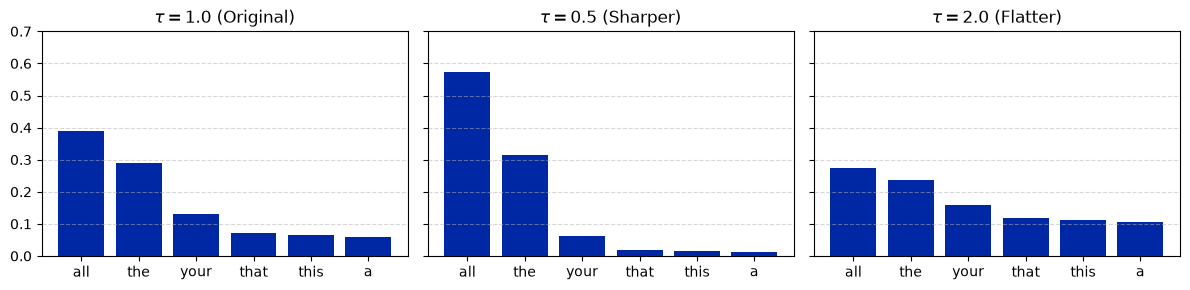


Filtered Distributions:
Token   P (tau=1)   Top-k (k=3)    Top-p (p=0.9)  
--------------------------------------------------
all     0.389       0.482          0.413          
the     0.288       0.357          0.306          
your    0.129       0.161          0.137          
that    0.071       0.000          0.075          
this    0.064       0.000          0.068          
a       0.058       0.000          0.000          



Empirical frequencies after 10,000 samples:
Token   k=3 target  k=3 empirical  p=0.9 target   p=0.9 empirical
-----------------------------------------------------------------
all     0.482       0.476          0.413          0.411          
the     0.357       0.362          0.306          0.307          
your    0.161       0.162          0.137          0.139          
that    0.000       0.000          0.075          0.073          
this    0.000       0.000          0.068          0.071          
a       0.000       0.000          0.000          0.000          


In [8]:
tokens_toy = ["all", "the", "your", "that", "this", "a"]
logits_toy = torch.tensor([1.2, 0.9, 0.1, -0.5, -0.6, -0.7])

# Temperature variations
p_tau1 = F.softmax(logits_toy / 1.0, dim=0)
p_tau05 = F.softmax(logits_toy / 0.5, dim=0)
p_tau2 = F.softmax(logits_toy / 2.0, dim=0)
cum_p_tau1 = torch.cumsum(p_tau1, dim=0)

print(f"{'Token':<8}{'Logit':<8}{'P(tau=1)':<12}{'Cumulative':<12}{'P(tau=0.5)':<12}{'P(tau=2.0)':<12}")
print("-" * 64)
for i in range(len(tokens_toy)):
    print(f"{tokens_toy[i]:<8}{logits_toy[i].item():<8.1f}{p_tau1[i].item():<12.3f}{cum_p_tau1[i].item():<12.3f}{p_tau05[i].item():<12.3f}{p_tau2[i].item():<12.3f}")

# Plot temperature effects
fig, axes = plt.subplots(1, 3, figsize=(12, 3), sharey=True)
axes[0].bar(tokens_toy, p_tau1.numpy(), color='#0028a5')
axes[0].set_title(r"$\tau = 1.0$ (Original)")
axes[1].bar(tokens_toy, p_tau05.numpy(), color='#0028a5')
axes[1].set_title(r"$\tau = 0.5$ (Sharper)")
axes[2].bar(tokens_toy, p_tau2.numpy(), color='#0028a5')
axes[2].set_title(r"$\tau = 2.0$ (Flatter)")
for ax in axes:
    ax.set_ylim(0, 0.7)
    ax.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# Top-k and Top-p implementation
def sample_top_k(logits, k):
    top_vals, top_indices = torch.topk(logits, k)
    probs = F.softmax(top_vals, dim=-1)
    full_probs = torch.zeros_like(logits)
    full_probs.scatter_(0, top_indices, probs)
    return full_probs

def sample_top_p(logits, p):
    probs = F.softmax(logits, dim=-1)
    sorted_probs, sorted_indices = torch.sort(probs, descending=True)
    cum_probs = torch.cumsum(sorted_probs, dim=-1)
    # Shortest prefix reaching p
    idx = (cum_probs >= p).nonzero(as_tuple=True)[0][0].item() + 1
    kept_indices = sorted_indices[:idx]
    kept_probs = probs[kept_indices]
    renorm_probs = kept_probs / kept_probs.sum()
    full_probs = torch.zeros_like(logits)
    full_probs.scatter_(0, kept_indices, renorm_probs)
    return full_probs

p_top3 = sample_top_k(logits_toy, k=3)
p_topp09 = sample_top_p(logits_toy, p=0.9)

print("\nFiltered Distributions:")
print(f"{'Token':<8}{'P (tau=1)':<12}{'Top-k (k=3)':<15}{'Top-p (p=0.9)':<15}")
print("-" * 50)
for i in range(len(tokens_toy)):
    print(f"{tokens_toy[i]:<8}{p_tau1[i].item():<12.3f}{p_top3[i].item():<15.3f}{p_topp09[i].item():<15.3f}")

# Verify with 10,000 empirical samples
torch.manual_seed(42)
samples_k = torch.multinomial(p_top3, num_samples=10000, replacement=True)
samples_p = torch.multinomial(p_topp09, num_samples=10000, replacement=True)

freq_k = torch.bincount(samples_k, minlength=len(tokens_toy)).float() / 10000
freq_p = torch.bincount(samples_p, minlength=len(tokens_toy)).float() / 10000

print("\nEmpirical frequencies after 10,000 samples:")
print(f"{'Token':<8}{'k=3 target':<12}{'k=3 empirical':<15}{'p=0.9 target':<15}{'p=0.9 empirical':<15}")
print("-" * 65)
for i in range(len(tokens_toy)):
    print(f"{tokens_toy[i]:<8}{p_top3[i].item():<12.3f}{freq_k[i].item():<15.3f}{p_topp09[i].item():<15.3f}{freq_p[i].item():<15.3f}")


In [9]:
# Comparing top-p adaptation on real GPT-2 distributions: Peaked vs. Flat
prompt_peaked = "The capital of France is Paris. The capital of Italy is"
prompt_flat = "The interesting thing about the"

for name, prompt in [("Peaked Context", prompt_peaked), ("Flat Context", prompt_flat)]:
    p_ids = tokenizer.encode(prompt, return_tensors="pt").to(DEVICE)
    with torch.no_grad():
        logits_next = model(p_ids).logits[0, -1]
    probs_next = F.softmax(logits_next, dim=-1)
    sorted_probs, sorted_indices = torch.sort(probs_next, descending=True)
    cum_probs = torch.cumsum(sorted_probs, dim=-1)
    
    # Tokens needed to reach 90% cumulative mass
    k_needed = (cum_probs >= 0.9).nonzero(as_tuple=True)[0][0].item() + 1
    top5_tokens = [tokenizer.decode(sorted_indices[i]) for i in range(5)]
    top5_p = [sorted_probs[i].item() for i in range(5)]
    
    print(f"{name}: {prompt!r}")
    print(f"  Top 5 candidates: {top5_tokens}")
    print(f"  Top 5 probabilities: {[round(x, 3) for x in top5_p]}")
    print(f"  Tokens needed to reach p=0.9 (nucleus size): {k_needed:,d} / 50,257\n")


Peaked Context: 'The capital of France is Paris. The capital of Italy is'
  Top 5 candidates: [' Rome', ' Milan', ' Florence', ' Naples', ' Venice']
  Top 5 probabilities: [0.494, 0.216, 0.064, 0.057, 0.041]
  Tokens needed to reach p=0.9 (nucleus size): 13 / 50,257

Flat Context: 'The interesting thing about the'
  Top 5 candidates: [' new', ' story', ' book', ' whole', ' game']
  Top 5 probabilities: [0.014, 0.01, 0.008, 0.008, 0.008]
  Tokens needed to reach p=0.9 (nucleus size): 9,842 / 50,257



### Read the result

1. **Temperature:** At $\tau=1$, the probabilities match the slide ($0.389, 0.288, 0.129, 0.071, 0.064, 0.058$) and the cumulative row reproduces $.389, .677, .806, .878, .942, 1.000$. Lowering $\tau$ to $0.5$ concentrates $57.4\%$ on `'all'`; raising $\tau$ to $2.0$ flattens it to $27.3\%$.
2. **Top-$k$ vs. Top-$p$:**
   - Top-$k$ ($k=3$) preserves exactly $3$ tokens, giving renormalized weights $0.482, 0.357, 0.161$.
   - Top-$p$ ($p=0.9$) requires $5$ tokens to reach $.942 \ge 0.9$, renormalizing over $5$ tokens.
3. **Adaptive Nucleus Size:**
   - On the peaked prompt (*"The capital of Italy is"*), the distribution concentrates on `' Rome'` ($49.4\%$) and only **$13$ tokens** suffice to reach $90\%$ probability mass.
   - On the open/flat prompt (*"The interesting thing about the"*), the highest token has only $1.4\%$ probability, and **$9,842$ tokens** are needed to reach $90\%$. Top-$p$ dynamically expands and contracts its candidate pool.

**Check yourself.**

1. What decoding method does Top-$k$ reduce to when $k=1$?
2. What happens to next-token probabilities as $\tau \to 0$ and as $\tau \to \infty$?
3. Does lowering temperature or setting a tight nucleus threshold make generation more factually truthful?

<details>
<summary>Solution: Decoding limits, temperature bounds, and factuality</summary>

1. When $k=1$, Top-$k$ selects the single token with highest logit ($i^* = \arg\max_i u_i$) with probability $1.0$, which is greedy decoding.
2. As $\tau \to 0$, the probability of the maximum logit token approaches $1.0$ (argmax / one-hot distribution). As $\tau \to \infty$, all scaled logits $u_i / \tau \to 0$, and the distribution approaches a discrete uniform distribution over the entire vocabulary ($P(i) = \frac{1}{|V|}$).
3. No. Temperature and sampling truncation affect sampling sharpness and diversity, not factual truth. If the model's highest logit corresponds to a common misconception, hallucination, or biased continuation, lowering temperature ensures that the incorrect token is generated with even higher certainty.
</details>


## N7. The Decoding Loop With and Without KV Cache

**Reusing earlier Keys and Values produces identical generated tokens with significantly less compute.**

Replays: *The Decoding Loop; Sequential Generation Repeats Work; KV Cache*.

In autoregressive generation, generating $T$ new tokens naively requires running $T$ separate forward passes:
- Step 1: feed prompt (length $m$).
- Step 2: feed prompt + token 1 (length $m+1$).
- $\dots$
- Step $t$: feed prompt + $t-1$ tokens (length $m+t-1$).

At step $t$, the naive loop recomputes the projections $Q, K, V$ for all previous tokens from scratch, even though earlier tokens cannot attend to later tokens through the causal mask.

**The Key-Value (KV) Cache:**
- At step 1 (prefill), compute and store $K$ and $V$ for all prompt tokens across all layers.
- At step $t > 1$ (decoding), compute $Q, K, V$ for the **single newest token only**.
- Append the new $K_t, V_t$ to the stored cache.
- The attention layer computes:
  $$\text{Attn}(Q_t, K_{\le t}, V_{\le t})$$
  producing the new representation $\mathbf{h}_t$ and next-token logits without re-encoding the history.

**Predict:** Will cached greedy generation produce bitwise identical token IDs to uncached generation? How will the generation time scale as sequence length grows?


In [10]:
import time

prompt = "Once upon a time"
prompt_ids = tokenizer.encode(prompt, return_tensors="pt").to(DEVICE)
num_new_tokens = 100  # budget: 100 greedy tokens on CPU or GPU

# Warm-up pass so neither loop pays one-time setup costs
with torch.no_grad():
    model(prompt_ids, use_cache=False)

# 1. Uncached generation loop (recomputes full prefix every step)
uncached_ids = prompt_ids.clone()
t0 = time.time()
for _ in range(num_new_tokens):
    with torch.no_grad():
        out = model(uncached_ids, use_cache=False)
        next_token = out.logits[:, -1, :].argmax(dim=-1, keepdim=True)
        uncached_ids = torch.cat([uncached_ids, next_token], dim=-1)
time_uncached = time.time() - t0

# 2. Cached generation loop
cached_ids = prompt_ids.clone()
t0 = time.time()
with torch.no_grad():
    # Prefill stage
    out = model(prompt_ids, use_cache=True)
    past_key_values = out.past_key_values
    next_token = out.logits[:, -1, :].argmax(dim=-1, keepdim=True)
    cached_ids = torch.cat([cached_ids, next_token], dim=-1)
    
    # Decoding stage: pass single token and cached states
    for _ in range(num_new_tokens - 1):
        out = model(next_token, past_key_values=past_key_values, use_cache=True)
        past_key_values = out.past_key_values
        next_token = out.logits[:, -1, :].argmax(dim=-1, keepdim=True)
        cached_ids = torch.cat([cached_ids, next_token], dim=-1)
time_cached = time.time() - t0

print(f"Generated text: {tokenizer.decode(uncached_ids[0])!r}")
print(f"\nIdentical generated token IDs? {torch.equal(uncached_ids, cached_ids)}")
print(f"Time without cache ({num_new_tokens} tokens): {time_uncached:.3f} s")
print(f"Time with cache ({num_new_tokens} tokens):    {time_cached:.3f} s")
print(f"Speedup factor: {time_uncached / time_cached:.2f}x")

# Inspect cache dimensions and memory footprint
def get_layer_kv(cache, layer_idx):
    if hasattr(cache, 'layers'): # transformers >= 4.45
        return cache.layers[layer_idx].keys, cache.layers[layer_idx].values
    elif hasattr(cache, 'key_cache'):
        return cache.key_cache[layer_idx], cache.value_cache[layer_idx]
    else:
        return cache[layer_idx][0], cache[layer_idx][1]

k_sample, v_sample = get_layer_kv(past_key_values, 0)
cached_tokens = k_sample.shape[2]  # the last generated token was never fed back
print(f"\nTokens in the sequence: {cached_ids.shape[1]}; tokens in the cache: {cached_tokens}")
print(f"Cache tensor dimensions per layer: [batch_size, num_heads, seq_len, head_dim]")
print(f"  Key cache shape:   {list(k_sample.shape)}")
print(f"  Value cache shape: {list(v_sample.shape)}")

# Total cache memory: 2 (K and V) * num_layers * batch * heads * seq_len * head_dim * sizeof(float32)
bytes_per_float = 4
total_cache_bytes = 2 * 12 * 1 * 12 * cached_tokens * 64 * bytes_per_float
print(f"Total KV cache memory for {cached_tokens} cached tokens: {total_cache_bytes / 2**20:.2f} MB")


Generated text: 'Once upon a time, the world was a place of great beauty and great danger. The world was a place of great danger, and the world was a place of great danger. The world was a place of great danger, and the world was a place of great danger. The world was a place of great danger, and the world was a place of great danger. The world was a place of great danger, and the world was a place of great danger. The world was a place of great danger, and the'

Identical generated token IDs? True
Time without cache (100 tokens): 2.611 s
Time with cache (100 tokens):    0.830 s
Speedup factor: 3.15x

Tokens in the sequence: 104; tokens in the cache: 103
Cache tensor dimensions per layer: [batch_size, num_heads, seq_len, head_dim]
  Key cache shape:   [1, 12, 103, 64]
  Value cache shape: [1, 12, 103, 64]
Total KV cache memory for 103 cached tokens: 7.24 MB


### Read the result

1. **Exact Equivalence:** `torch.equal(uncached_ids, cached_ids)` is `True`. KV caching is an exact mathematical refactoring of attention, not an approximation.
2. **What the cache saves:**
   - Without cache, step $t$ re-runs the whole stack on all $m+t-1$ tokens: projections, FFNs, and attention for every earlier position are recomputed.
   - With cache, step $t$ runs the stack on the newest token only: its projections and FFN cost $\mathcal{O}(1)$ in the sequence length. Its attention still reads all $m+t-1$ cached keys and values, so that part stays $\mathcal{O}(t)$ per step.
   - The measured speedup depends on hardware and on the number of new tokens; compare it with a shorter budget (e.g. 25 tokens).
3. **Memory Trade-Off:** The KV cache stores $2 \times L$ tensors of shape $[1, h, t, d_k]$. The last generated token is never fed back, so the cache holds one token fewer than the sequence. Even for about a hundred tokens of GPT-2 small, it already takes several megabytes; for long contexts (e.g. $t = 128\text{k}$) and larger models, cache memory reaches tens of gigabytes.

**Check yourself.**

1. Why does the causal attention mask make KV caching valid for autoregressive models, whereas it would fail for a bidirectional model like BERT?
2. Why does training a GPT model not require a KV cache?

<details>
<summary>Solution: Causal validity and training parallelism</summary>

1. In causal attention, $M_{ij} = -\infty$ for $j > i$. Token $i$'s key and value representations depend strictly on tokens $\le i$; future tokens generated at steps $> i$ can never change $K_i$ or $V_i$. In a bidirectional model (like BERT), adding a new token at the end changes the contextual representations of all earlier tokens across every layer, so cached states would become invalid immediately.
2. During training, the entire target sequence is already available. Because attention is causal, all $n$ positions can attend to their valid prefixes in a single parallel matrix multiplication (Section N3). Sequential generation is an inference-time constraint where tokens must be sampled one by one.
</details>


## N8. The Prefix Specifies the Task

**The prefix conditioning shapes continuation format, but small models handle task transfer weakly.**

Replays: *Fine-Tuning, Zero-Shot, Few-Shot; The Prefix Specifies the Task; Larger Models Use the Context Better*.

GPT-2 demonstrated that an autoregressive language model trained purely on next-token prediction can perform diverse tasks without updating model weights (in-context conditioning).
As shown in the GPT-2 paper (Radford et al., 2019), formatting the prompt specifies the desired task:
- **Zero-Shot:** Provide a single input and prompt the continuation:
  `English: cheese\nFrench:`
- **Few-Shot:** Prepend $k$ demonstrations before the target query:
  `English: water\nFrench: eau\n\nEnglish: car\nFrench: voiture\n\nEnglish: tree\nFrench: arbre\n\nEnglish: cheese\nFrench:`

We test 5 common vocabulary words (`cat`, `dog`, `house`, `apple`, `book`) on GPT-2 small under greedy decoding, extracting the first line of continuation.

**Predict:**
- Does the few-shot prefix change what GPT-2 small writes after `French:` compared to zero-shot?
- Will GPT-2 small (124M) produce accurate French translations?


In [11]:
test_words = ["cat", "dog", "house", "apple", "book"]
gold_french = ["chat", "chien", "maison", "pomme", "livre"]

# Zero-shot prompts
zero_shot_prompts = [f"English: {w}\nFrench:" for w in test_words]

# 3-shot prompt demonstrations
demonstrations = (
    "English: water\nFrench: eau\n\n"
    "English: car\nFrench: voiture\n\n"
    "English: tree\nFrench: arbre\n\n"
)
few_shot_prompts = [f"{demonstrations}English: {w}\nFrench:" for w in test_words]

def generate_continuation(prompt_text, max_new=6):
    enc = tokenizer(prompt_text, return_tensors="pt").to(DEVICE)
    input_ids = enc.input_ids
    with torch.no_grad():
        out = model.generate(
            input_ids,
            attention_mask=enc.attention_mask,
            max_new_tokens=max_new,
            do_sample=False,
            pad_token_id=tokenizer.eos_token_id
        )
    new_tokens = out[0, input_ids.shape[1]:]
    full_str = tokenizer.decode(new_tokens)
    # Extract first line up to newline
    first_line = full_str.strip().split("\n")[0].strip()
    return first_line

print(f"{'English':<10}{'Gold French':<14}{'Zero-Shot Output':<20}{'3-Shot Output':<20}")
print("-" * 64)
for w, gold, p_zero, p_few in zip(test_words, gold_french, zero_shot_prompts, few_shot_prompts):
    out_zero = generate_continuation(p_zero)
    out_few = generate_continuation(p_few)
    print(f"{w:<10}{gold:<14}{out_zero!r:<20}{out_few!r:<20}")


English   Gold French   Zero-Shot Output    3-Shot Output       
----------------------------------------------------------------
cat       chat          'cat'               'cette'             


dog       chien         'dog'               'cot'               
house     maison        'house'             'cette'             


apple     pomme         'apple'             'aubre'             
book      livre         'book'              'cette'             


### Read the result

Inspect the outputs in the table:
- Under **zero-shot**, GPT-2 small copies the English word in every case: `English: X\nFrench:` alone does not tell it that a translation is expected.
- Under **3-shot**, the demonstrations change the continuation: GPT-2 small now writes French-looking words (`'cette'`, `'aubre'`, `'cot'`) instead of copying. None of them is the correct translation.

The prefix specifies the task, and the model picks up that a French word should follow. Producing the *right* French word is a matter of competence that GPT-2 small at $124\text{M}$ parameters lacks. Radford et al. (2019) and Brown et al. (2020) report that in-context translation becomes usable only in much larger models ($1.5\text{B}$ to $175\text{B}$ parameters).

**Check yourself.**

1. Why do 3 demonstration pairs change *what kind* of word follows, even though the translations themselves stay wrong?
2. Why is evaluating a model on 5 hand-picked words insufficient to claim anything general about its zero-shot capabilities?

<details>
<summary>Solution: In-context format priming vs. rigorous benchmark evaluation</summary>

1. Attention can copy the pattern of the demonstrations (after `French:` comes a French word, then a blank line) from the context itself. Retrieving the correct French word for a new English word needs knowledge stored in the weights, which is the harder part for a small model.
2. A sample of 5 words has enormous variance and can be confounded by word frequency, tokenization subword splits, or memorized collocations in the pretraining corpus. Reliable evaluation requires standard test suites (e.g., WMT test sets with BLEU/ChrF scoring) across diverse grammatical classes and frequencies.
</details>
